# Exploratory Data Analysis

Explores the processed outputs of `01_data_collection.ipynb`:

| Table | File | Grain |
|---|---|---|
| `players` | `data/processed/top300_players.csv` | one row per ladder player |
| `matches` | `data/processed/player_matches.csv` | one row per (player, match) |

## Setup

In [42]:
%%capture

pip install -r requirements.txt

In [3]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import requests

sys.path.append(str(Path.cwd().parent))  # make `src` importable from notebooks/
from src.config import PROCESSED_DIR

pd.set_option("display.max_columns", None)

## Load Data
Both CSVs were saved with the pandas index as the first column, so `index_col=0` drops it back into the index.

In [4]:
players = pd.read_csv(PROCESSED_DIR / "top300_players.csv", index_col=0)
matches = pd.read_csv(
    PROCESSED_DIR / "player_matches.csv",
    index_col=0,
    parse_dates=["gameCreation"],
    dtype={"patch": str},  # keep e.g. "16.10" from becoming 16.1
)

print(f"players: {players.shape} | matches: {matches.shape}")
players.head()

players: (300, 14) | matches: (30000, 33)


,ladder_rank,puuid,leaguePoints,rank,wins,losses,veteran,inactive,freshBlood,hotStreak,games,win_rate,riotIdGameName,riotIdTagline
0,1,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,4041,I,358,245,True,False,False,False,603,0.593698,C9 Loki,kr3
1,2,8WfFV8TPkd6DIaajOHARJAJR8BJF8U9sTmFRzt4SfhmSe7...,4013,I,558,352,True,False,False,True,910,0.613187,never type,1998
2,3,lmPjvRxc2s1Ha9Wbb8y6SkcbvZUF1vN86QNM_Ib4cOQMRt...,3523,I,636,504,True,False,False,True,1140,0.557895,Lobby Admin,FIGHT
3,4,XwiJ6fkuW_8DC9PDNvlKYAFlgm4e6j952DE0TqJWWt9Rxl...,3228,I,698,545,True,False,False,False,1243,0.561545,Davemon,NA1
4,5,i627oHfp0rlM_VbmJMFze12mD6UYaiao9Hl6XTmYHKrSON...,3217,I,497,421,True,False,False,False,918,0.541394,LFT Sheiden,PHL1


In [5]:
matches.head()

,matchId,puuid,gameCreation,gameDuration_min,gameVersion,patch,riotIdGameName,riotIdTagline,championName,teamPosition,teamId,win,kills,deaths,assists,totalMinionsKilled,neutralMinionsKilled,goldEarned,totalDamageDealtToChampions,damageDealtToObjectives,visionScore,wardsPlaced,wardsKilled,champLevel,timeCCingOthers,firstBloodKill,turretKills,gameEndedInEarlySurrender,cs,cs_per_min,gold_per_min,kda,is_remake
0,NA1_5659998027,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-14 03:55:52.729,17.866667,16.20.824.8524,16.20,C9 Loki,kr3,Akali,MIDDLE,200,False,3,4,1,163,0,6874,7993,1773,18,5,3,12,3,False,0,False,163,9.123134,384.738806,1.000000,False
1,NA1_5659953897,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-14 03:01:47.670,32.816667,16.20.824.8524,16.20,C9 Loki,kr3,Pyke,UTILITY,200,False,5,9,16,32,0,10206,14722,821,118,46,15,13,33,False,0,False,32,0.975114,311.000508,2.333333,False
2,NA1_5659936919,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-14 02:34:36.093,23.583333,16.20.824.8524,16.20,C9 Loki,kr3,Lissandra,MIDDLE,100,True,2,5,10,218,0,10148,15105,4909,23,11,2,15,32,False,0,False,218,9.243816,430.303887,2.400000,False
3,NA1_5659295272,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-13 01:39:45.362,31.933333,16.20.824.8524,16.20,C9 Loki,kr3,Ahri,MIDDLE,200,False,5,7,8,267,0,13145,26669,5570,59,13,16,16,25,False,1,False,267,8.361169,411.638831,1.857143,False
4,NA1_5659128611,QbUo_rUH-xUixdyYxetIJf0C6QIOA_tXBWmrOkRo1_B8iV...,2026-10-12 21:38:46.451,26.216667,16.20.824.8524,16.20,C9 Loki,kr3,Akali,MIDDLE,200,True,19,3,7,232,4,16496,30399,15322,23,6,3,17,4,True,3,False,236,9.001907,629.218055,8.666667,False


## Champion Classes
Class tags come from Data Dragon (Riot's static data site). The first tag is the main class.


In [6]:
DDRAGON = "https://ddragon.leagueoflegends.com"
version = requests.get(f"{DDRAGON}/api/versions.json", timeout=10).json()[0]  # latest patch
champs = requests.get(f"{DDRAGON}/cdn/{version}/data/en_US/champion.json", timeout=10).json()["data"]
champ_classes = pd.DataFrame([
    {"champ_key": key.lower(),
     "primary_class": c["tags"][0]}
    for key, c in champs.items()
])
# Match on lowercase names: match-v5 says "FiddleSticks", Data Dragon says "Fiddlesticks"
matches["champ_key"] = matches["championName"].str.lower()
matches = matches.merge(champ_classes, on="champ_key", how="left").drop(columns="champ_key")
umatches = matches.drop_duplicates("matchId")
print(f"Data Dragon {version} | unmapped champions: {matches.loc[matches.primary_class.isna(), 'championName'].unique()}")
matches["primary_class"].value_counts()


Data Dragon 16.20.1 | unmapped champions: []


primary_class
Fighter     7928
Mage        6986
Marksman    5751
Assassin    4016
Tank        2991
Support     2328
Name: count, dtype: int64

## Null Values – `Matches`
Count and percentage of missing values in every column of the matches table.

In [7]:
matches_nulls = pd.DataFrame({
    "dtype": matches.dtypes,
    "null_count": matches.isna().sum(),
    "null_pct": (matches.isna().mean() * 100).round(2),
})

print(f"Total nulls: {matches_nulls.null_count.sum()} | columns with nulls: {(matches_nulls.null_count > 0).sum()}/{len(matches_nulls)}")
matches_nulls
matches_nulls[matches_nulls["null_count"] > 0]

Total nulls: 3 | columns with nulls: 1/34


,dtype,null_count,null_pct
teamPosition,object,3,0.01


There are 3 rows containing null values for the column 'teamPosition'. We can look at these specific rows to see what's going on.

In [8]:
matches[matches['teamPosition'].isna()]

,matchId,puuid,gameCreation,gameDuration_min,gameVersion,patch,riotIdGameName,riotIdTagline,championName,teamPosition,teamId,win,kills,deaths,assists,totalMinionsKilled,neutralMinionsKilled,goldEarned,totalDamageDealtToChampions,damageDealtToObjectives,visionScore,wardsPlaced,wardsKilled,champLevel,timeCCingOthers,firstBloodKill,turretKills,gameEndedInEarlySurrender,cs,cs_per_min,gold_per_min,kda,is_remake,primary_class
6859,NA1_5624278048,xGwmbjg6AQ_yUMtlxE07wPYlEv4yJjhFeZpp1EoPCqJA2G...,2026-08-19 04:16:12.621,2.066667,16.16.804.9184,16.16,twtv kaidojungle,IWNL,Seraphine,NaN,200,False,0,0,0,0,0,622,0,0,0,0,0,1,0,False,0,True,0,0.0,300.967742,0.0,True,Support
11778,NA1_5647543712,Y98pwQ3M4rbyvTn7BKJboT6RNvreqFxjGhQVI5yymuo66h...,2026-09-23 17:23:55.198,3.733333,16.19.820.7193,16.19,GLIDE GLIDE,SMURF,Jinx,NaN,200,False,0,0,0,0,0,826,0,0,0,0,0,1,0,False,0,False,0,0.0,221.250000,0.0,True,Marksman
29811,NA1_5660269852,aGuNpPXy5i8HJpZsxykNN12EfhJJJcTocRdYs83q1G5kC-...,2026-10-14 19:57:19.534,3.400000,16.20.824.8524,16.20,SHAK,HAHA,Alistar,NaN,100,False,0,1,0,0,0,826,0,0,0,0,0,1,0,False,0,False,0,0.0,242.941176,0.0,True,Tank


These 3 games look to be remakes, which we are going to filter out anyways in a later step, so we can effectively ignore these.

In [9]:
matches = matches[matches['is_remake'] == False]

In [10]:
matches.shape

(29719, 34)

So remakes account for 281 of the 30000 games, or around 1% of the games.

## Unique Matches

Since the challenger league is entirely made up of the top 300 players, it is very likely that a lot of the observations in `Matches` are going to share the same match. We can check the number of uniques matches by counting the distinct count of matchIDs.

In [11]:
matches['matchId'].nunique()

14230

Under half of the observations in `matches` are from unique games. This shouldn't matter for the most part when studying more of the player level metrics like kills per death, but will bias game wide statistics like game length. So just for the purpose of briefly exploring game duration for now, we will create a deduplicated copy of `matches`.

In [12]:
umatches = matches.drop_duplicates('matchId')
umatches.shape

(14230, 34)

## Distribution of game length

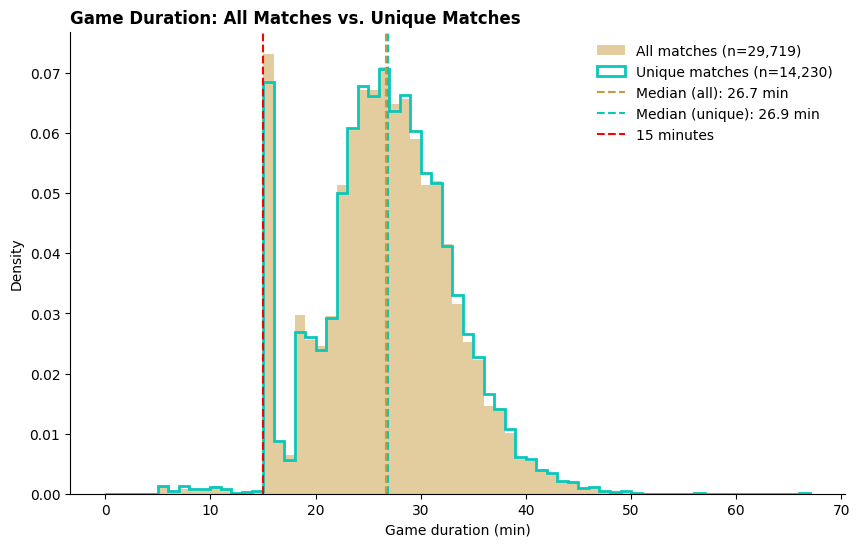

,all_rows,unique_matches
count,29719.00,14230.00
mean,26.68,26.82
std,6.28,6.30
min,5.00,5.00
25%,22.88,23.05
50%,26.72,26.85
75%,30.73,30.90
max,66.53,66.53


In [44]:
GOLD, BLUE = "#C89B3C", "#0AC8B9"
bins = np.arange(0, matches["gameDuration_min"].max() + 1, 1)  # 1-minute bins, shared by both

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(matches["gameDuration_min"], bins=bins, density=True, color=GOLD, alpha=0.5,
        label=f"All matches (n={len(matches):,})")
ax.hist(umatches["gameDuration_min"], bins=bins, density=True, histtype="step", lw=2, color=BLUE,
        label=f"Unique matches (n={len(umatches):,})")

for data, color, name in [(matches, GOLD, "all"), (umatches, BLUE, "unique")]:
    med = data["gameDuration_min"].median()
    ax.axvline(med, color=color, ls="--", lw=1.5, label=f"Median ({name}): {med:.1f} min")
ax.axvline(15, color= 'red', ls="--", lw=1.5, label= "15 minutes")
ax.set_title("Game Duration: All Matches vs. Unique Matches", loc="left", fontweight="bold")
ax.set_xlabel("Game duration (min)")
ax.set_ylabel("Density")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

pd.DataFrame({
    "all_rows": matches["gameDuration_min"].describe(),
    "unique_matches": umatches["gameDuration_min"].describe(),
}).round(2)


The distribution of game duration across the unique matches and the entire dataset look to be approximately the same, with the mean marginally higher by about 1 second across the unique matches. The most apparent difference between the 2 distributions is the difference in the spike at around the 15 minute mark.

The overall distrubution looks to be bimodal, with peaks at 15 minutes and around the mean at 27 minutes. The most likely reason for such a high frequency of 15 minute games is due to forfeits, where teams have the option to surrender early up to the 15 minute mark.

In [14]:
counts_unique, _ = np.histogram(umatches["gameDuration_min"], bins=bins)

bin_freqs = pd.DataFrame({
    "bin": pd.IntervalIndex.from_breaks(bins, closed="left"),  # [a, b); numpy also includes the top edge in the last bin
    "count": counts_unique,
    "pct": counts_unique / counts_unique.sum() * 100,
})
bin_freqs.nlargest(5, "pct")


,bin,count,pct
26,"[26.0, 27.0)",1005,7.062544
15,"[15.0, 16.0)",974,6.844694
24,"[24.0, 25.0)",966,6.788475
28,"[28.0, 29.0)",944,6.633872
25,"[25.0, 26.0)",941,6.612790


Most matches ended due to early surrender generally take a few seconds longer than 15 minutes as the surrender votes need to go through, essentially padding a few seconds to the match. This is likely the reason for such a large concentration of games between 15 and 16 minutes.

### Performance by Champion Class


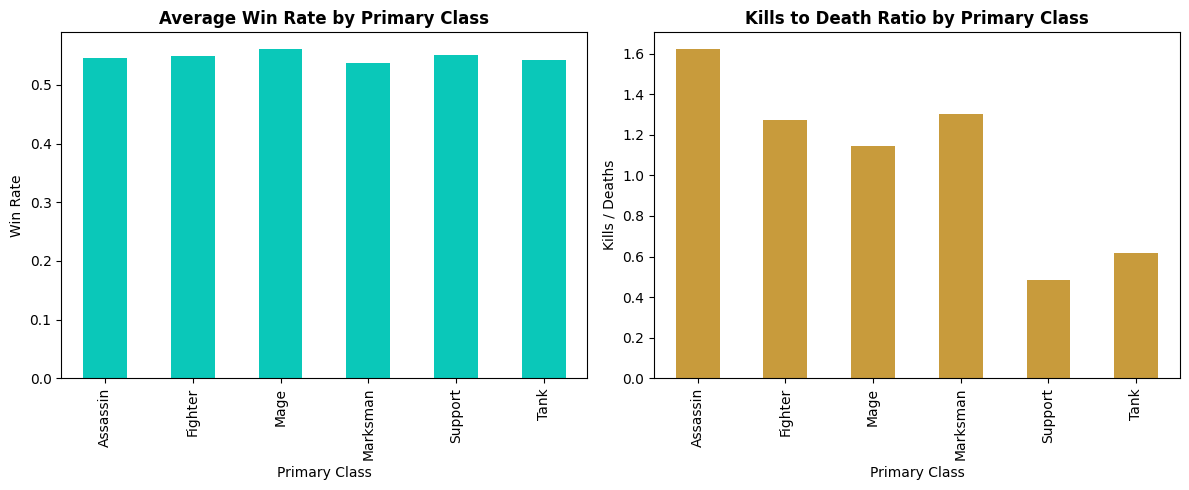

In [20]:
# 1. Group by primary_class, calculate mean win rate and aggregate K/D ratio
class_stats = matches.groupby("primary_class").agg(
    win_rate=("win", "mean"),
    total_kills=("kills", "sum"),
    total_deaths=("deaths", "sum")
)
class_stats["kd_ratio"] = class_stats["total_kills"] / class_stats["total_deaths"]

# 2. Plot the metrics using Matplotlib
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

class_stats["win_rate"].plot(kind="bar", ax=ax1, color="#0AC8B9")
ax1.set_title("Average Win Rate by Primary Class", fontweight="bold")
ax1.set_ylabel("Win Rate")
ax1.set_xlabel("Primary Class")

class_stats["kd_ratio"].plot(kind="bar", ax=ax2, color="#C89B3C")
ax2.set_title("Kills to Death Ratio by Primary Class", fontweight="bold")
ax2.set_ylabel("Kills / Deaths")
ax2.set_xlabel("Primary Class")

plt.tight_layout()
plt.show()



Across all primary classes, win rates remain consistently above 50%, reflecting the high skill level of Challenger-tier players.

Marksmen sit at the lowest average win rate (~53.8%), likely reflecting their high vulnerability and team-dependency in solo queue environments.


Unlike win rate, K/D ratio varies dramatically based on class design and role responsibilities. Assassins lead with a 1.62 K/D, followed by Marksmen (1.30) and Fighters (1.27). Tanks (0.62) and Supports (0.49) have sub-1.0 K/D ratios, as their kits prioritize crowd control, vision, peeling, and facilitating kills for teammates rather than securing final blows.

### How do win rates vary across primary classes by game duration?

Primary classes often hit different peaks in strength and performance at different points in the game. For instance, marksmen are typically weak in the early game as they lack the necessary items to bolster their damage, whereas assassins are stronger early to mid game as they already have a lot of damage built into their abilities.

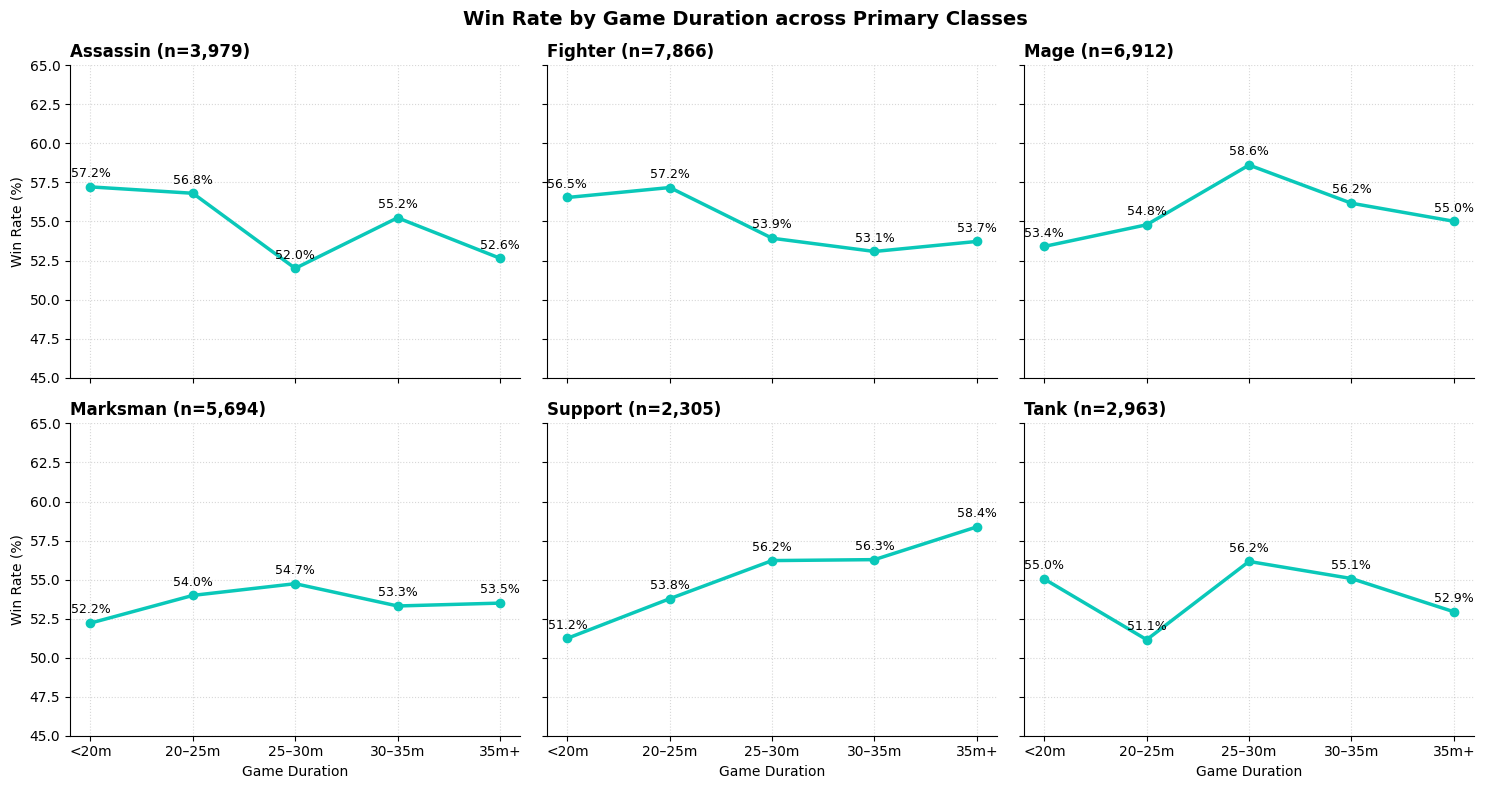

In [45]:
# 1. Exclude remakes and bin game duration
duration_bins = [0, 20, 25, 30, 35, 100]
bin_labels = ["<20m", "20–25m", "25–30m", "30–35m", "35m+"]
matches["duration_bin"] = pd.cut(
    matches["gameDuration_min"],
    bins=duration_bins,
    labels=bin_labels,
    right=False,
)

# 2. Aggregate win rate and game count per class and duration
class_duration = (
    matches.groupby(["primary_class", "duration_bin"], observed=False)["win"]
    .agg(win_rate="mean", total_games="count")
    .reset_index()
)
class_duration["win_rate_pct"] = class_duration["win_rate"] * 100

# 3. Create 2x3 subplot grid
classes = sorted(class_duration["primary_class"].dropna().unique())
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.flatten()

BLUE = "#0AC8B9"

for i, cls in enumerate(classes):
    ax = axes[i]
    subset = class_duration[class_duration["primary_class"] == cls]
    total_n = subset["total_games"].sum()

    # Line chart with markers
    ax.plot(
        subset["duration_bin"],
        subset["win_rate_pct"],
        marker="o",
        color=BLUE,
        linewidth=2.5,
        markersize=6,
    )

    # Point annotations
    for _, row in subset.iterrows():
        ax.annotate(
            f"{row['win_rate_pct']:.1f}%",
            (row["duration_bin"], row["win_rate_pct"]),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=9,
        )

    ax.set_title(f"{cls} (n={total_n:,})", loc="left", fontweight="bold")
    ax.set_ylim(45, 65)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.spines[["top", "right"]].set_visible(False)

    if i in [0, 3]:
        ax.set_ylabel("Win Rate (%)")
    if i >= 3:
        ax.set_xlabel("Game Duration")

fig.suptitle("Win Rate by Game Duration across Primary Classes", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


These plots indeed support the idea that win rates do vary quite significantly by primary classes, when specifically looking at these win rates by game duration. As we hypothesized earlier, games where marksmen didn't have enough time to build their items often performed more poorly the earlier the game ended, whereas assassins peaked in their win rates when the game ended prior to 20 minutes.

These trends of course vary by different primary classes, but we do infact notice changes in win rates by primary class as the game durations vary

### Do KD ratios have any effect on win rates?

Rather than just focusing on total kills or deaths in a given game, does looking at a players total kills/ total deaths ratio prove to be a more appealing feature when studying what contributes to win rates?

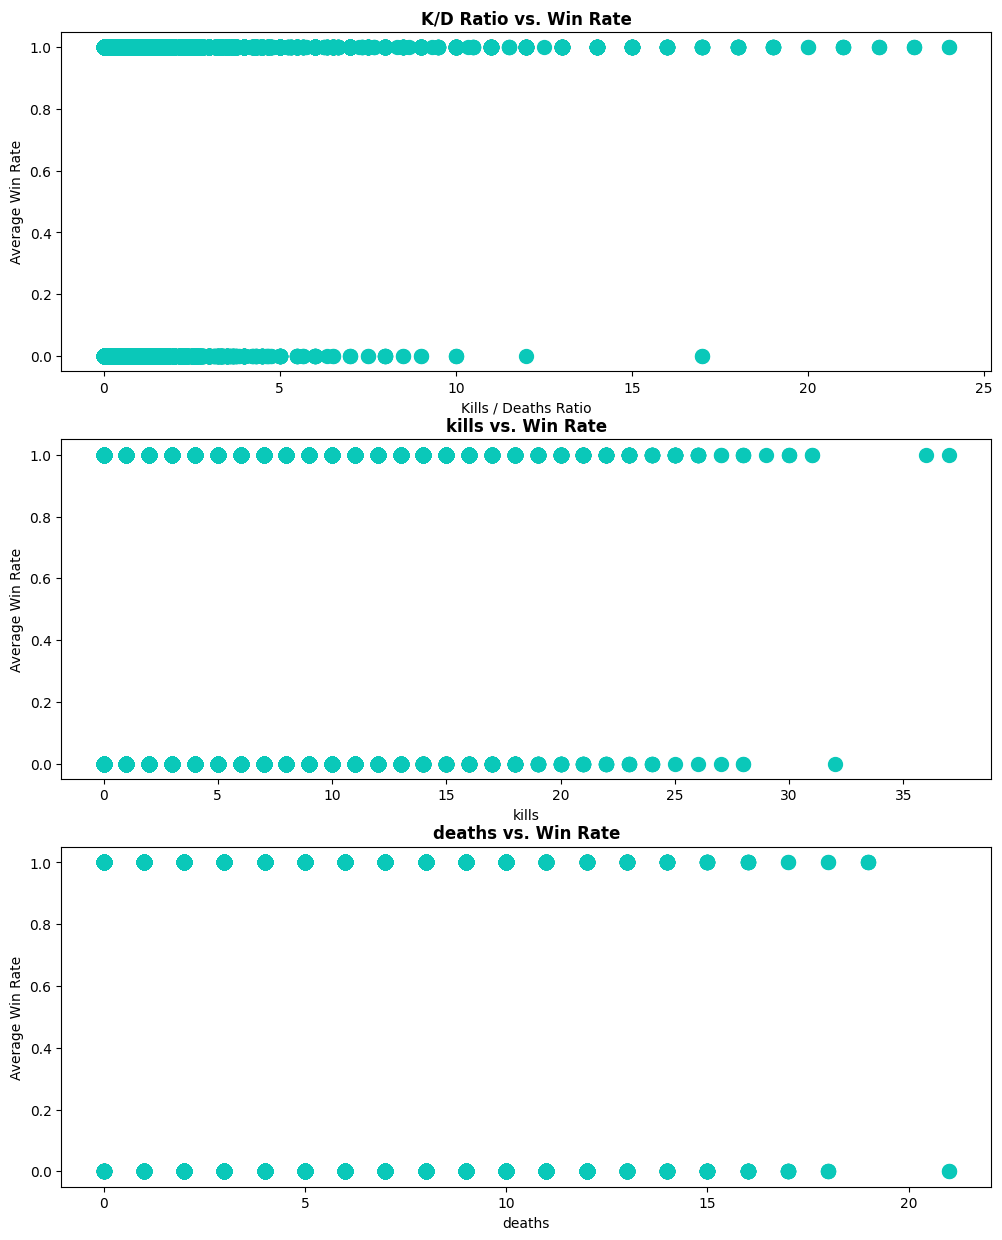

In [30]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 15))


player_stats = matches.copy()

player_stats["kd_ratio"] = player_stats["kills"] / player_stats["deaths"]
ax1.scatter(player_stats["kd_ratio"], player_stats["win"], color="#0AC8B9", s=100)
ax1.set_title("K/D Ratio vs. Win Rate", fontweight="bold")
ax1.set_xlabel("Kills / Deaths Ratio")
ax1.set_ylabel("Average Win Rate")

ax2.scatter(player_stats["kills"], player_stats["win"], color="#0AC8B9", s=100)
ax2.set_title("kills vs. Win Rate", fontweight="bold")
ax2.set_xlabel("kills")
ax2.set_ylabel("Average Win Rate")

ax3.scatter(player_stats["deaths"], player_stats["win"], color="#0AC8B9", s=100)
ax3.set_title("deaths vs. Win Rate", fontweight="bold")
ax3.set_xlabel("deaths")
ax3.set_ylabel("Average Win Rate")

plt.show()


Based on the scatterplot above, there does appear to be an association between the K/D ratio and wins, as opposed to just using kills or deaths. We could even fit a sigmoid relative well across the points, emblatic of a logistic regression we could run to predict wins.

In [23]:
player_stats.columns

Index(['matchId', 'puuid', 'gameCreation', 'gameDuration_min', 'gameVersion',
       'patch', 'riotIdGameName', 'riotIdTagline', 'championName',
       'teamPosition', 'teamId', 'win', 'kills', 'deaths', 'assists',
       'totalMinionsKilled', 'neutralMinionsKilled', 'goldEarned',
       'totalDamageDealtToChampions', 'damageDealtToObjectives', 'visionScore',
       'wardsPlaced', 'wardsKilled', 'champLevel', 'timeCCingOthers',
       'firstBloodKill', 'turretKills', 'gameEndedInEarlySurrender', 'cs',
       'cs_per_min', 'gold_per_min', 'kda', 'is_remake', 'primary_class',
       'kd_ratio'],
      dtype='object')

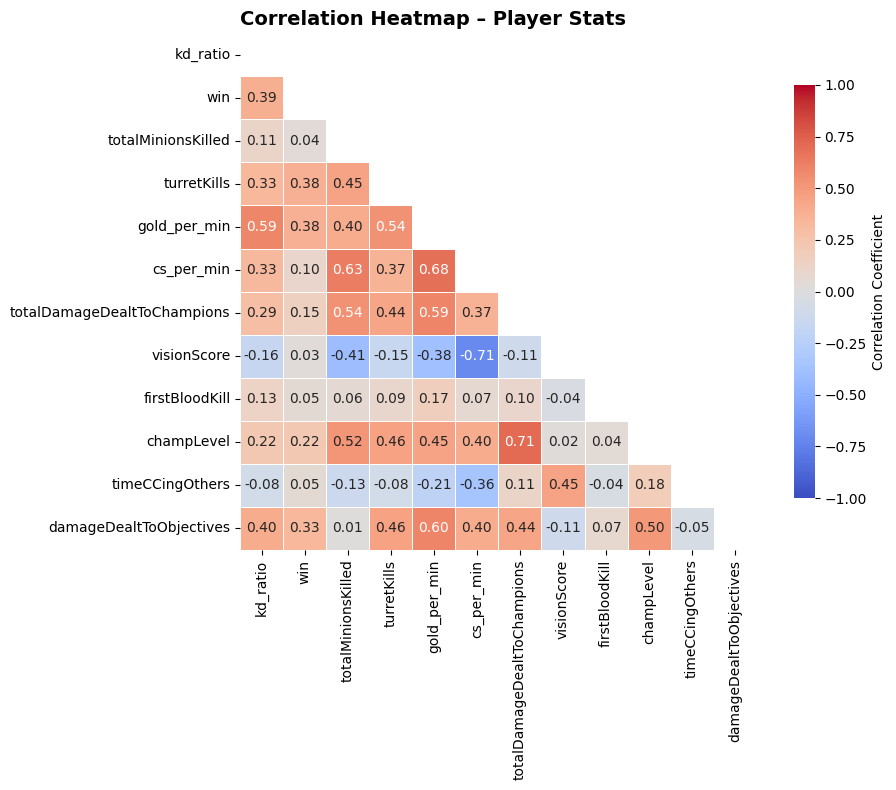

In [31]:
# Compute correlation matrix for numeric columns
corr = player_stats[[
"kd_ratio", "win", 'totalMinionsKilled', 'primary_class', 'turretKills', 'gold_per_min', 'cs_per_min', 'totalDamageDealtToChampions',
'visionScore', 'firstBloodKill', 'champLevel', 'timeCCingOthers', 'damageDealtToObjectives' ]].corr(numeric_only=True)
# Mask the upper triangle to remove duplicate information
mask = np.triu(np.ones_like(corr, dtype=bool))
# Set up the figure
fig, ax = plt.subplots(figsize=(10, 8))
# Draw the heatmap
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",       # Or "vlag" / "RdBu_r"
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Correlation Coefficient"},
    ax=ax
)
ax.set_title("Correlation Heatmap – Player Stats", loc="left", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

Using the correlation heatmap above, we can see features most correlated to winning appear to be `kd_ratio`, `damageDealtToObjectives`, `turretkills`, and `gold_per_min`. We will use these features later on to give us a better understanding of what affects win rate when fitting a model.

### Does win rate matter more than games played when climbing the league points ladder?

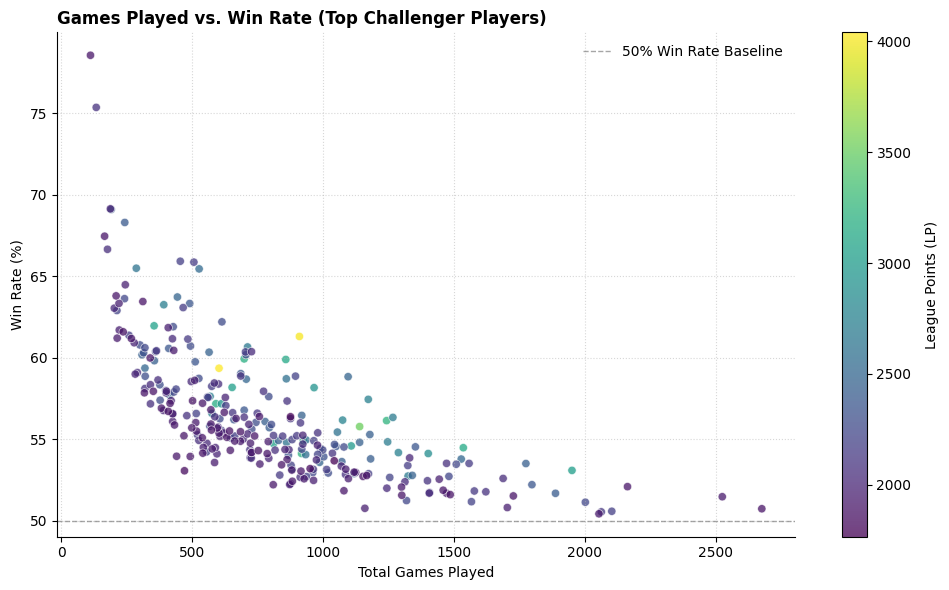

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))


scatter = ax.scatter(
    players["games"],
    players["win_rate"] * 100,
    c=players["leaguePoints"],
    cmap="viridis",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.5,
)

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("League Points (LP)", labelpad=10)

# Labels & styling
ax.set_title("Games Played vs. Win Rate (Top Challenger Players)", loc="left", fontweight="bold")
ax.set_xlabel("Total Games Played")
ax.set_ylabel("Win Rate (%)")
ax.axhline(50, color="gray", linestyle="--", linewidth=1, alpha=0.7, label="50% Win Rate Baseline")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(frameon=False, loc="upper right")

plt.tight_layout()
plt.show()


Average win rate appears to be more of a driver in total league points compared to total games played. So players in the challenger league are better off focusing on their individual gameplay rather than grinding through the ladder in hopes of reaching higher league points

### How much does time of day alone effect a players performance across their matches?

It is a common claim across many players in the league of legends community that playing past midnight often leads to a worsened performance, we can use data to check this claim

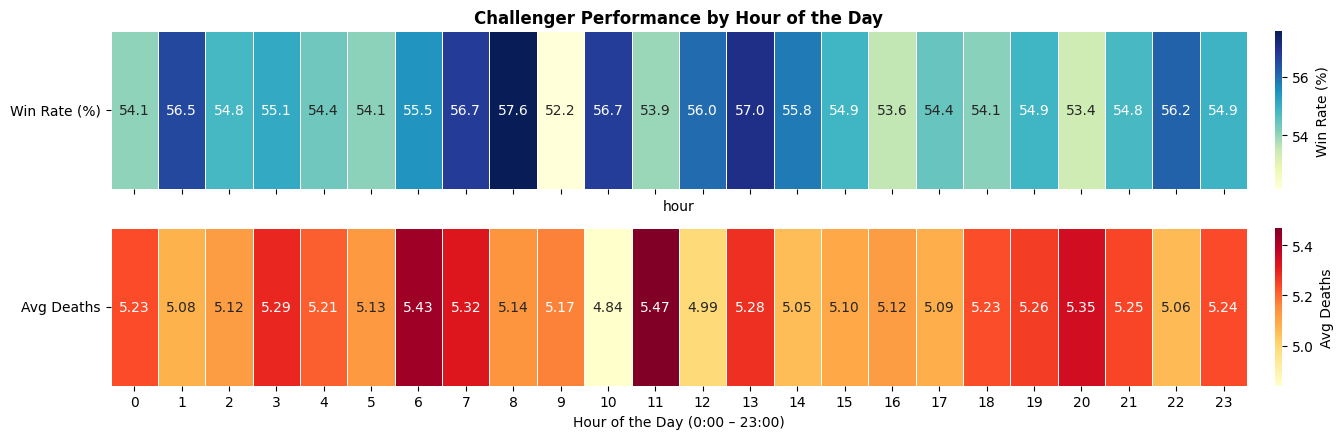

In [40]:
# Extract hour of match start (0 - 23)
matches["hour"] = matches["gameCreation"].dt.hour

# Calculate hourly win rate (%) and average deaths
hourly_stats = matches.groupby("hour").agg(
    win_rate=("win", lambda x: x.mean() * 100),
    avg_deaths=("deaths", "mean"),
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 4.5), sharex=True)

# 1. Win Rate Heatmap
sns.heatmap(
    hourly_stats[["win_rate"]].T,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={"label": "Win Rate (%)", "pad": 0.02},
    linewidths=0.5,
    ax=ax1,
)
ax1.set_title("Challenger Performance by Hour of the Day", loc="center", fontweight="bold")
ax1.set_ylabel("")
ax1.set_yticklabels(["Win Rate (%)"], rotation=0)

# 2. Average Deaths Heatmap
sns.heatmap(
    hourly_stats[["avg_deaths"]].T,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    cbar_kws={"label": "Avg Deaths", "pad": 0.02},
    linewidths=0.5,
    ax=ax2,
)
ax2.set_ylabel("")
ax2.set_yticklabels(["Avg Deaths"], rotation=0)
ax2.set_xlabel("Hour of the Day (0:00 – 23:00)")

plt.tight_layout()
plt.show()


It appears the claim that playing during certain parts of the day effects performance remains largely unfounded, at least according to match data. These winrates appear relatively uniform across all hours of the day.